Note: you may need to restart the kernel to use updated packages.
S0 = S2 before month 30: True
S1 = S3 before month 30: True
                                                   S0          S1          S2          S3
Peak sorting error, months 30-39                0.118       0.102       0.154       0.131
Minimum AI accuracy                             0.288       0.344       0.242       0.323
Minimum operator skill                          0.240       0.288       0.240       0.280
First month generation > capacity              43.000      91.000      30.000      30.000
Recovery below capacity (month)                   NaN         NaN         NaN      39.000
Peak contamination stock (t)                  615.611     130.072     937.643     161.345
Contamination stock, month 100 (t)            615.611     130.072     937.643     146.109
Minimum recycled share                          0.211       0.432       0.157       0.404
Emissions, month 100 (tCO2-eq/month)         1987.924    1658.00

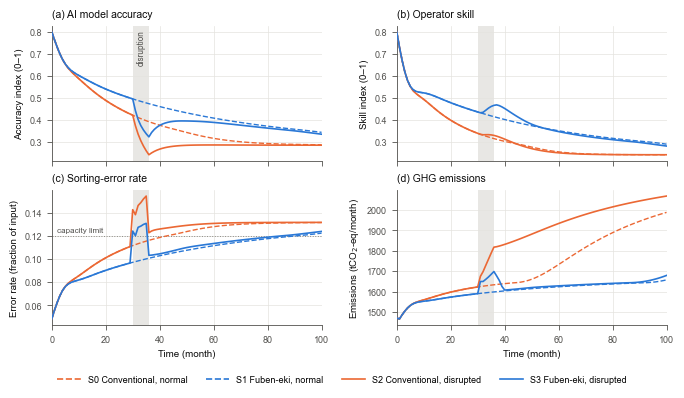

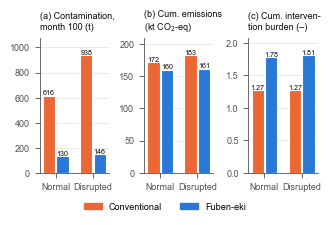

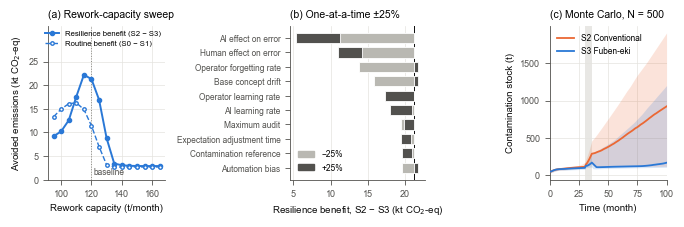

Baseline: S2 - S3 = 21,273 tCO2-eq (11.7 %), extra burden 42 %
DiD: -306 t contamination, -9,877 tCO2-eq
Capacity sweep: benefit peaks at 115 t/month (22,192 tCO2-eq); at 165 t/month it is 2,892 tCO2-eq; extra burden 41-43 %
Monte Carlo: emission reduction median 8.1 % (5-95 %: 2.2-12.0 %), extra burden 38 % (24-55 %)
Share of MC runs with S3 < S2 emissions: 100.0 %
Most influential parameters (OAT): AI effect on error, Human effect on error, Operator forgetting rate, Base concept drift


In [1]:
%pip install pysd

from pathlib import Path
import warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import pysd

warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# 1. Settings
MODEL_PATH = Path("Fuben-Eki.mdl")    # Vensim model file
OUT_DIR    = Path("figures")          # output folder
OUT_DIR.mkdir(exist_ok=True)

FINAL_TIME = 100                      # months
DISRUPTION = (30, 36)                 # STEP(1,30) - STEP(1,36)
CAPACITY   = 120                      # baseline rework capacity (t/month)
SA_RANGE   = 0.25                     # +/- 25 % for OAT and Monte Carlo
MC_RUNS    = 500                      # Monte Carlo samples
MC_SEED    = 42
CAP_SWEEP  = list(range(95, 166, 5))  # rework capacities for the sweep
DPI        = 300

# 2. Figure style 
plt.rcParams.update({
    "font.family": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.labelcolor": "#0b0b0b", "axes.grid": True,
    "grid.color": "#e4e3df", "grid.linewidth": 0.5,
    "legend.frameon": False, "savefig.dpi": DPI,
})
CONV, FE = "#eb6834", "#2a78d6"                  # conventional (orange), fuben-eki (blue)
INK, MUTED, SHADE = "#0b0b0b", "#8a8984", "#d9d8d3"
STYLE = {"S0": (CONV, "--"), "S1": (FE, "--"), "S2": (CONV, "-"), "S3": (FE, "-")}
LABEL = {"S0": "S0 Conventional, normal", "S1": "S1 Fuben-eki, normal",
         "S2": "S2 Conventional, disrupted", "S3": "S3 Fuben-eki, disrupted"}
CM = 1 / 2.54
SINGLE_COL, DOUBLE_COL = 8.4 * CM, 17.4 * CM     # Procedia CIRP column widths

#  3. Model and scenarios 
# PySD keeps changed parameters between runs, so two separate model objects are used
m_normal = pysd.read_vensim(str(MODEL_PATH))     # Shock Adv overridden with 0
m_shock  = pysd.read_vensim(str(MODEL_PATH))     # Shock Adv keeps STEP(1,30)-STEP(1,36)

SCENARIOS = {"S0": (0, False), "S1": (1, False), "S2": (0, True), "S3": (1, True)}

BASE = {  # parameters varied in the sensitivity analysis (baseline values, View 2)
    "Learn rate Adv": 0.6, "Forget rate Adv": 0.1, "ACC learn rate Adv": 0.4,
    "Concept drift base Adv": 0.05, "Trust speed Adv": 0.5, "Shock Sensitivity Adv": 0.8,
    "Automation Bias Adv": 0.25, "Human Effect Adv": 0.6, "Ai Effect Adv": 0.7,
    "Learning rate": 0.2, "Forgetting rate": 0.05, "Expected adjustment time": 6,
    "Audit adjust time": 2, "Max Audit": 0.3, "Drift shock magnitude Adv": 0.1,
    "Quality Sensitivity Adv": 3, "Error ref": 0.12, "Contam ref": 120,
}
NICE = {
    "Learn rate Adv": "Operator learning rate", "Forget rate Adv": "Operator forgetting rate",
    "ACC learn rate Adv": "AI learning rate", "Concept drift base Adv": "Base concept drift",
    "Trust speed Adv": "Trust adjustment speed", "Shock Sensitivity Adv": "Trust shock sensitivity",
    "Automation Bias Adv": "Automation bias", "Human Effect Adv": "Human effect on error",
    "Ai Effect Adv": "AI effect on error", "Learning rate": "Fuben-eki commitment rate",
    "Forgetting rate": "Fuben-eki forgetting rate", "Expected adjustment time": "Expectation adjustment time",
    "Audit adjust time": "Audit adjustment time", "Max Audit": "Maximum audit",
    "Drift shock magnitude Adv": "Disruption drift magnitude", "Quality Sensitivity Adv": "Quality sensitivity",
    "Error ref": "Error reference", "Contam ref": "Contamination reference",
}
OUTPUTS = ["Fuben eki", "Audit Intensity Adv", "Operator Skill Adv", "AI Model Accuracy Adv",
           "Trust AI Adv", "Sorting Error rate Adv", "Contamination generation Adv",
           "Contamination stock Adv", "Quality Index Adv", "Recycled share Adv",
           "Total Emission Adv", "Cumulative emission Adv", "Human intervention burden"]

def run_scenario(name, overrides=None, capacity=CAPACITY):
    switch, disrupted = SCENARIOS[name]
    params = dict(BASE)
    params.update({"Fuben eki switch": switch, "Rework Capacity Adv": capacity})
    if overrides:
        params.update(overrides)
    model = m_shock if disrupted else m_normal
    if not disrupted:
        params["Shock Adv"] = 0
    df = model.run(params=params, return_columns=OUTPUTS, final_time=FINAL_TIME)
    dt = df.index[1] - df.index[0]
    df["Cumulative burden"] = np.concatenate([[0], np.cumsum(df["Human intervention burden"].values[:-1] * dt)])
    return df

def run_all(overrides=None, capacity=CAPACITY):
    return {s: run_scenario(s, overrides, capacity) for s in SCENARIOS}

def first_exceed(series, limit=CAPACITY):
    idx = series[series > limit].index
    return idx.min() if len(idx) else np.nan

def recovery_month(stock, limit=CAPACITY + 5, after=DISRUPTION[1]):
    post = stock[stock.index > after]
    idx = post[post <= limit].index
    return idx.min() if len(idx) else np.nan

def shade(ax):
    ax.axvspan(*DISRUPTION, color=SHADE, alpha=0.6, lw=0, zorder=0)

#  4. Baseline runs and consistency check 
D = run_all()
pre = slice(0, DISRUPTION[0] - 1)
ok1 = np.allclose(D["S0"].loc[pre].values, D["S2"].loc[pre].values)
ok2 = np.allclose(D["S1"].loc[pre].values, D["S3"].loc[pre].values)
print(f"S0 = S2 before month {DISRUPTION[0]}: {ok1}")
print(f"S1 = S3 before month {DISRUPTION[0]}: {ok2}")
assert ok1 and ok2, "Scenario set-up is inconsistent - check the model file."

#  5. Scenario metrics 
rows = {}
for s, d in D.items():
    win = d.loc[DISRUPTION[0]:DISRUPTION[1] + 3]
    rows[s] = {
        "Peak sorting error, months 30-39": win["Sorting Error rate Adv"].max(),
        "Minimum AI accuracy": d["AI Model Accuracy Adv"].min(),
        "Minimum operator skill": d["Operator Skill Adv"].min(),
        "First month generation > capacity": first_exceed(d["Contamination generation Adv"]),
        "Recovery below capacity (month)": recovery_month(d["Contamination stock Adv"]) if SCENARIOS[s][1] else np.nan,
        "Peak contamination stock (t)": d["Contamination stock Adv"].max(),
        "Contamination stock, month 100 (t)": d["Contamination stock Adv"].iloc[-1],
        "Minimum recycled share": d["Recycled share Adv"].min(),
        "Emissions, month 100 (tCO2-eq/month)": d["Total Emission Adv"].iloc[-1],
        "Cumulative emissions, month 100 (tCO2-eq)": d["Cumulative emission Adv"].iloc[-1],
        "Cumulative intervention burden": d["Cumulative burden"].iloc[-1],
        "Mean audit intensity": d["Audit Intensity Adv"].mean(),
    }
metrics = pd.DataFrame(rows)
E = metrics.loc["Cumulative emissions, month 100 (tCO2-eq)"]
S = metrics.loc["Contamination stock, month 100 (t)"]
B = metrics.loc["Cumulative intervention burden"]
summary = pd.Series({
    "Resilience benefit S2-S3 (tCO2-eq)": E.S2 - E.S3,
    "Resilience benefit S2-S3 (%)": 100 * (E.S2 - E.S3) / E.S2,
    "Routine benefit S0-S1 (tCO2-eq)": E.S0 - E.S1,
    "Disruption penalty, conventional (tCO2-eq)": E.S2 - E.S0,
    "Disruption penalty, fuben-eki (tCO2-eq)": E.S3 - E.S1,
    "DiD emissions (tCO2-eq)": (E.S3 - E.S1) - (E.S2 - E.S0),
    "DiD contamination stock (t)": (S.S3 - S.S1) - (S.S2 - S.S0),
    "Extra burden S3 vs S2 (%)": 100 * (B.S3 / B.S2 - 1),
})
metrics.to_csv(OUT_DIR / "scenario_metrics.csv")
summary.to_csv(OUT_DIR / "scenario_summary.csv", header=["value"])
print(metrics.round(3).to_string())
print(summary.round(1).to_string())

#  6. Fig. 2 - human-AI response to emissions (4 panels) 
panels = [("AI Model Accuracy Adv",  "(a) AI model accuracy",   "Accuracy index (0–1)"),
          ("Operator Skill Adv",     "(b) Operator skill",      "Skill index (0–1)"),
          ("Sorting Error rate Adv", "(c) Sorting-error rate",  "Error rate (fraction of input)"),
          ("Total Emission Adv",     "(d) GHG emissions",       "Emissions (tCO$_2$-eq/month)")]
fig, axs = plt.subplots(2, 2, figsize=(DOUBLE_COL, 10.0 * CM), sharex=True)
for ax, (var, title, ylab) in zip(axs.flat, panels):
    shade(ax)
    for s in ["S0", "S1", "S2", "S3"]:
        c, ls = STYLE[s]
        ax.plot(D[s].index, D[s][var], color=c, ls=ls, lw=1.2 if ls == "-" else 1.0, zorder=3)
    ax.set_title(title, loc="left", color=INK)
    ax.set_ylabel(ylab)
    ax.set_xlim(0, FINAL_TIME)
    if var == "Sorting Error rate Adv":   # capacity-equivalent error = 120/1000
        ax.axhline(CAPACITY / 1000, color=MUTED, lw=0.7, ls=":", zorder=2)
        ax.text(2, CAPACITY / 1000 + 0.0028, "capacity limit", color="#52514e", fontsize=5.8)
for ax in axs[1]:
    ax.set_xlabel("Time (month)")
axs[0, 0].text(sum(DISRUPTION) / 2, 0.97, "disruption", transform=axs[0, 0].get_xaxis_transform(),
               ha="center", va="top", fontsize=6, color="#52514e", rotation=90)
handles = [Line2D([0], [0], color=STYLE[s][0], ls=STYLE[s][1], lw=1.2) for s in LABEL]
fig.tight_layout(rect=(0, 0.06, 1, 1), h_pad=0.8, w_pad=2.0)
fig.legend(handles, LABEL.values(), ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0.0),
           fontsize=6.5, handlelength=2.6)
fig.savefig(OUT_DIR / "Fig2_dynamics.png")
plt.show()

#  7. Fig. 3 - outcomes 
outcomes = [(S, "(a) Contamination,\nmonth 100 (t)", "{:.0f}"),
            (E / 1000, "(b) Cum. emissions\n(kt CO$_2$-eq)", "{:.0f}"),
            (B, "(c) Cum. interven-\ntion burden (–)", "{:.2f}")]
fig, axs = plt.subplots(1, 3, figsize=(SINGLE_COL, 5.6 * CM))
x, w = np.array([0, 1]), 0.36
for ax, (M, title, fmt) in zip(axs, outcomes):
    for j, (normal, disrupted, colour) in enumerate([("S0", "S2", CONV), ("S1", "S3", FE)]):
        vals = [M[normal], M[disrupted]]
        bars = ax.bar(x + (j - 0.5) * w, vals, w * 0.92, color=colour, edgecolor="white", linewidth=0.8, zorder=3)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=5.2, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(["Normal", "Disrupted"])
    ax.set_title(title, loc="left", fontsize=6.5, color=INK)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
fig.tight_layout(rect=(0, 0.08, 1, 1), w_pad=0.6)
fig.legend([Patch(color=CONV), Patch(color=FE)], ["Conventional", "Fuben-eki"],
           ncol=2, loc="lower center", bbox_to_anchor=(0.5, 0.0), fontsize=6.5)
fig.savefig(OUT_DIR / "Fig3_outcomes.png")
plt.show()

#  8. Sensitivity analysis 
def evaluate(overrides=None, capacity=CAPACITY, keep_series=False):
    R = run_all(overrides, capacity)
    e = {s: R[s]["Cumulative emission Adv"].iloc[-1] for s in R}
    st = {s: R[s]["Contamination stock Adv"].iloc[-1] for s in R}
    b = {s: R[s]["Cumulative burden"].iloc[-1] for s in R}
    out = {
        "AvoidEm": e["S2"] - e["S3"],
        "AvoidPct": 100 * (e["S2"] - e["S3"]) / e["S2"],
        "RoutineEm": e["S0"] - e["S1"],
        "DiDEm": (e["S3"] - e["S1"]) - (e["S2"] - e["S0"]),
        "DiDStock": (st["S3"] - st["S1"]) - (st["S2"] - st["S0"]),
        "ExtraBurdenPct": 100 * (b["S3"] / b["S2"] - 1),
        "S3recovers": not np.isnan(recovery_month(R["S3"]["Contamination stock Adv"], capacity + 5)),
    }
    if keep_series:
        out["series"] = {s: R[s]["Contamination stock Adv"].values for s in ("S2", "S3")}
    return out

base_eval = evaluate()

# (a) rework-capacity sweep
cap = pd.DataFrame([dict(evaluate(capacity=c), RC=c) for c in CAP_SWEEP]).set_index("RC")
cap.to_csv(OUT_DIR / "sensitivity_capacity.csv")

# (b) one-at-a-time +/- 25 %
rows = []
for p, v in BASE.items():
    lo, hi = evaluate({p: v * (1 - SA_RANGE)}), evaluate({p: v * (1 + SA_RANGE)})
    rows.append({"parameter": p, "label": NICE[p],
                 "low_AvoidEm": lo["AvoidEm"], "high_AvoidEm": hi["AvoidEm"],
                 "low_DiDEm": lo["DiDEm"], "high_DiDEm": hi["DiDEm"],
                 "low_ExtraBurdenPct": lo["ExtraBurdenPct"], "high_ExtraBurdenPct": hi["ExtraBurdenPct"]})
oat = pd.DataFrame(rows)
oat["max_dev"] = np.maximum((oat.low_AvoidEm - base_eval["AvoidEm"]).abs(),
                            (oat.high_AvoidEm - base_eval["AvoidEm"]).abs())
oat = oat.sort_values("max_dev", ascending=False).reset_index(drop=True)
oat.to_csv(OUT_DIR / "sensitivity_oat.csv", index=False)

# (c) Monte Carlo, Latin hypercube, uniform +/- 25 % (about 30-60 s)
rng = np.random.default_rng(MC_SEED)
keys = list(BASE)
k = len(keys)
U = (np.argsort(rng.random((MC_RUNS, k)), axis=0) + rng.random((MC_RUNS, k))) / MC_RUNS
mc_rows, bands = [], {"S2": [], "S3": []}
for i in range(MC_RUNS):
    sample = {p: BASE[p] * (1 - SA_RANGE + 2 * SA_RANGE * U[i, j]) for j, p in enumerate(keys)}
    r = evaluate(sample, keep_series=True)
    series = r.pop("series")
    for s in bands:
        bands[s].append(series[s])
    mc_rows.append({**r, **sample})
mc = pd.DataFrame(mc_rows)
bands = {s: np.array(v) for s, v in bands.items()}
mc.to_csv(OUT_DIR / "sensitivity_montecarlo.csv", index=False)

#  9. Fig. 4 - sensitivity 
fig, axs = plt.subplots(1, 3, figsize=(DOUBLE_COL, 5.8 * CM), gridspec_kw={"width_ratios": [1, 1.15, 1]})

ax = axs[0]
ax.axvline(CAPACITY, color=MUTED, lw=0.7, ls=":")
ax.text(CAPACITY + 1, 1, "baseline", fontsize=6, color="#52514e")
ax.plot(cap.index, cap["AvoidEm"] / 1000, color=FE, lw=1.4, marker="o", ms=3,
        label="Resilience benefit (S2 − S3)", zorder=3)
ax.plot(cap.index, cap["RoutineEm"] / 1000, color=FE, lw=1.0, ls="--", marker="o", ms=2.5, mfc="white",
        label="Routine benefit (S0 − S1)", zorder=3)
ax.set_xlabel("Rework capacity (t/month)")
ax.set_ylabel("Avoided emissions (kt CO$_2$-eq)")
ax.set_title("(a) Rework-capacity sweep", loc="left")
ymax = 5 * np.ceil(max(cap["AvoidEm"].max(), cap["RoutineEm"].max()) / 5000)
ax.set_ylim(0, ymax * 1.3)
ax.set_yticks(np.arange(0, ymax + 1, 5))
ax.legend(fontsize=5.6, loc="upper right", handlelength=1.8, borderaxespad=0.1)

ax = axs[1]
top = oat.head(10).iloc[::-1]
y = np.arange(len(top))
b0 = base_eval["AvoidEm"] / 1000
for yi, lo_v, hi_v in zip(y, top.low_AvoidEm / 1000 - b0, top.high_AvoidEm / 1000 - b0):
    for val, col in sorted([(lo_v, "#b9b8b2"), (hi_v, "#52514e")], key=lambda q: -abs(q[0])):
        ax.barh(yi, val, left=b0, height=0.7, color=col, edgecolor="white", lw=0.6, zorder=3)
ax.axvline(b0, color=INK, lw=0.7)
ax.set_yticks(y)
ax.set_yticklabels(top.label, fontsize=6)
ax.set_xlabel("Resilience benefit, S2 − S3 (kt CO$_2$-eq)")
ax.set_title(f"(b) One-at-a-time ±{int(SA_RANGE * 100)}%", loc="left")
ax.grid(axis="y", visible=False)
ax.legend([Patch(color="#b9b8b2"), Patch(color="#52514e")],
          [f"−{int(SA_RANGE * 100)}%", f"+{int(SA_RANGE * 100)}%"], fontsize=6, loc="lower left")

ax = axs[2]
t = D["S2"].index.values
for s, colour in [("S2", CONV), ("S3", FE)]:
    p5, p50, p95 = np.percentile(bands[s], [5, 50, 95], axis=0)
    ax.fill_between(t, p5, p95, color=colour, alpha=0.18, lw=0, zorder=2)
    ax.plot(t, p50, color=colour, lw=1.3, zorder=3)
shade(ax)
ax.set_xlim(0, FINAL_TIME)
ax.set_xlabel("Time (month)")
ax.set_ylabel("Contamination stock (t)")
ax.set_title(f"(c) Monte Carlo, N = {MC_RUNS}", loc="left")
ax.legend([Line2D([0], [0], color=CONV, lw=1.3), Line2D([0], [0], color=FE, lw=1.3)],
          ["S2 Conventional", "S3 Fuben-eki"], fontsize=6, loc="upper left")
fig.tight_layout(w_pad=1.2)
fig.savefig(OUT_DIR / "Fig4_sensitivity.png")
plt.show()

#  10. Key numbers for the text 
peak = cap["AvoidEm"].idxmax()
q = mc["AvoidPct"].quantile([0.05, 0.5, 0.95])
qb = mc["ExtraBurdenPct"].quantile([0.05, 0.5, 0.95])
print(f"Baseline: S2 - S3 = {summary['Resilience benefit S2-S3 (tCO2-eq)']:,.0f} tCO2-eq "
      f"({summary['Resilience benefit S2-S3 (%)']:.1f} %), extra burden {summary['Extra burden S3 vs S2 (%)']:.0f} %")
print(f"DiD: {summary['DiD contamination stock (t)']:,.0f} t contamination, {summary['DiD emissions (tCO2-eq)']:,.0f} tCO2-eq")
print(f"Capacity sweep: benefit peaks at {peak} t/month ({cap.loc[peak, 'AvoidEm']:,.0f} tCO2-eq); "
      f"at {CAP_SWEEP[-1]} t/month it is {cap['AvoidEm'].iloc[-1]:,.0f} tCO2-eq; "
      f"extra burden {cap['ExtraBurdenPct'].min():.0f}-{cap['ExtraBurdenPct'].max():.0f} %")
print(f"Monte Carlo: emission reduction median {q[0.5]:.1f} % (5-95 %: {q[0.05]:.1f}-{q[0.95]:.1f} %), "
      f"extra burden {qb[0.5]:.0f} % ({qb[0.05]:.0f}-{qb[0.95]:.0f} %)")
print(f"Share of MC runs with S3 < S2 emissions: {100 * (mc.AvoidEm > 0).mean():.1f} %")
print(f"Most influential parameters (OAT): {', '.join(oat.label.head(4))}")